# Shallow Neural Network with one hidden layer

<a name='1'></a>
# 1 - Packages

First import all the packages that you will need during this assignment.

- [numpy](https://www.numpy.org/) is the fundamental package for scientific computing with Python.
- [pandas](https://www.w3schools.com/python/pandas/pandas_intro.asp#:~:text=What%20is%20Pandas%3F,by%20Wes%20McKinney%20in%202008.) used for working with data sets.
- [sklearn](http://scikit-learn.org/stable/) provides simple and efficient tools for data mining and data analysis. 
- [matplotlib](http://matplotlib.org) is a library for plotting graphs in Python.
- testCases provides some test examples to assess the correctness of your functions

In [1]:
# Package imports
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler


<a name='2'></a>
# 2 - Load the Dataset


In [2]:
# Loading the data
weather_2021 = pd.read_csv("Data/ninja_weather_2021.csv", comment="#")
weather_2022 = pd.read_csv("Data/ninja_weather_2022.csv", comment="#")
weather_2023 = pd.read_csv("Data/ninja_weather_2023.csv", comment="#")
weather_2024 = pd.read_csv("Data/ninja_weather_2024.csv", comment="#")
weather_2025 = pd.read_csv("Data/ninja_weather_2025.csv", comment="#")

pv_2021 = pd.read_csv("Data/ninja_pv_2021.csv", comment="#")
pv_2022 = pd.read_csv("Data/ninja_pv_2022.csv", comment="#")
pv_2023 = pd.read_csv("Data/ninja_pv_2023.csv", comment="#")
pv_2024 = pd.read_csv("Data/ninja_pv_2024.csv", comment="#")
pv_2025 = pd.read_csv("Data/ninja_pv_2025.csv", comment="#")

# put the years together
weather = pd.concat([weather_2021, weather_2022, weather_2023, weather_2024, weather_2025], ignore_index=True)
pv = pd.concat([pv_2021, pv_2022, pv_2023, pv_2024, pv_2025], ignore_index=True)

# merge weather and pv into one big data set (matched by timestamp)
data = pd.merge(weather, pv, on="time")

data["time"] = pd.to_datetime(data["time"])    # timestamps as datetime
data = data.set_index("time")                  # datetime index

time = data.index                              # keep the timestamps
input_data = data.values                       # .values converts a pandas dataframe to a numpy array

In [3]:
#Categorizing the data into inputs (x) and outputs (y) as well as training set and testing set
split = int((time < "2025-01-01").sum())      # training: all hours before 2025, test: 2025
# split = int(0.8 * input_data.shape[0])      # alternative: 80/20 split

train_set_x_orig = input_data[:split, 0:8] # columns: 8 columns inputs, last one output
test_set_x_orig = input_data[split:, 0:8]
train_set_y_orig = input_data[:split, -1:]
test_set_y_orig = input_data[split:, -1:]

In [4]:
#Normalization process not here, only in cv-step

In [5]:
m_train = train_set_x_orig.shape[0]
m_test = test_set_x_orig.shape[0]
print ("Number of training examples: m_train = " + str(m_train))
print ("Number of testing examples: m_test = " + str(m_test))

Number of training examples: m_train = 35064
Number of testing examples: m_test = 8760


<a name='3'></a>
## 3 - Neural Network model

**Mathematically**:

For one example $x^{(i)}$:
$$
z^{[1] (i)} =  W^{[1]} x^{(i)} + b^{[1]}\tag{1}
$$ 
$$
a^{[1] (i)} = \tanh(z^{[1] (i)})\tag{2}
$$
$$
z^{[2] (i)} = W^{[2]} a^{[1] (i)} + b^{[2]}\tag{3}
$$
$$
\hat{y}^{(i)} = a^{[2] (i)} = \sigma(z^{ [2] (i)})\tag{4}
$$

Given the predictions on all the examples, you can also compute the cost $J$ as follows: 
$$J = - \frac{1}{m} \sum\limits_{i = 0}^{m} \large\left(\small y^{(i)}\log\left(a^{[2] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[2] (i)}\right)  \large  \right) \small \tag{5}$$

<a name='3-1'></a>
### 3.1 - Defining the neural network structure ####



In [6]:
def layer_sizes(X, Y):

    n_x = X.shape[0]
    n_y = Y.shape[0]

    return (n_x, n_y)

<a name='3-2'></a>
### 3.2 - Initialize the model's parameters ####

<a name='ex-3'></a>
### Exercise 3 -  initialize_parameters

Create a function as `initialize_parameters()`, which receives n_x, n_h, and n_y as inputs. As output, create a python dictionary containing parameters W1, b1, w2, and b2 with their initial values. 

Hint:
- Make sure your parameters' sizes are right. Refer to the neural network figure above if needed.

In [7]:
# initialize_parameters
def initialize_parameters(n_x,n_h,n_y):
   
    W1 = np.random.randn(n_h, n_x) * 0.01
    b1 = np.zeros((n_h,1))
    W2 = np.random.randn(n_y, n_h) * 0.01
    b2 = np.zeros((n_y,1))
    
    parameters = {
        "W1" : W1,
        "b1" : b1,
        "W2" : W2,
        "b2" : b2
        }
   
    return parameters

In [8]:
def sigmoid(z):
    s=1/(1+np.exp(-z))
    return s

<a name='3-3'></a>
### 3.3 - The Loop 

<a name='ex-4'></a>
### Exercise 4 - forward_propagation

Create a function as `forward_propagation()` which receives X and parameters as inputs. Then use the following equations:

$$
Z^{[1]} =  W^{[1]} X + b^{[1]}\tag{6}
$$ 
$$
A^{[1]} = \tanh(Z^{[1]})\tag{7}
$$
$$
Z^{[2]} = W^{[2]} A^{[1]} + b^{[2]}\tag{8}
$$
$$
\hat{Y} = A^{[2]} = \sigma(Z^{[2]})\tag{9}
$$

As output, make a dictionary named "cache" and put Z1, A1, Z2, A2 in it. Finally return A2 ansd cache.

In [9]:
def forward_propagation(X, parameters):
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    b1 = parameters["b1"]
    b2 = parameters["b2"]

    Z1 = W1 @ X + b1                 # matrix multiplicaation either with @ instead of * or with np.dot() or np.matmul()
    A1 = np.tanh((Z1))
    Z2 = W2 @ A1 + b2
    A2 = sigmoid((Z2))

    cache = {
        "Z1" : Z1,
        "A1" : A1,
        "Z2" : Z2,
        "A2" : A2
    }

    return A2, cache

<a name='3-4'></a>
### 3.4 - Compute the Cost

Now that you've computed $A^{[2]}$ (in the Python variable "`A2`"), which contains $a^{[2](i)}$ for all examples, you can compute the cost function as follows:

$$J = - \frac{1}{m} \sum\limits_{i = 1}^{m} \large{(} \small y^{(i)}\log\left(a^{[2] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[2] (i)}\right) \large{)} \small\tag{10}$$

<a name='ex-5'></a>


In [10]:
def compute_cost(A2, Y):
    m = Y.shape[1]
    logprobs = np.multiply(np.log(A2), Y) + np.multiply(np.log(1 - A2), (1 - Y))
    cost = -1/m * np.sum(logprobs)
    
    cost = float(np.squeeze(cost))  
    return cost

<a name='3-5'></a>
### 3.5 - Backpropagation

<!-- $\frac{\partial \mathcal{J} }{ \partial z_{2}^{(i)} } = \frac{1}{m} (a^{[2](i)} - y^{(i)})$

$\frac{\partial \mathcal{J} }{ \partial W_2 } = \frac{\partial \mathcal{J} }{ \partial z_{2}^{(i)} } a^{[1] (i) T} $

$\frac{\partial \mathcal{J} }{ \partial b_2 } = \sum_i{\frac{\partial \mathcal{J} }{ \partial z_{2}^{(i)}}}$

$\frac{\partial \mathcal{J} }{ \partial z_{1}^{(i)} } =  W_2^T \frac{\partial \mathcal{J} }{ \partial z_{2}^{(i)} } * ( 1 - a^{[1] (i) 2}) $

$\frac{\partial \mathcal{J} }{ \partial W_1 } = \frac{\partial \mathcal{J} }{ \partial z_{1}^{(i)} }  X^T $

$\frac{\partial \mathcal{J} _i }{ \partial b_1 } = \sum_i{\frac{\partial \mathcal{J} }{ \partial z_{1}^{(i)}}}$

- Note that $*$ denotes elementwise multiplication.
- The notation you will use is common in deep learning coding:
    - dW1 = $\frac{\partial \mathcal{J} }{ \partial W_1 }$
    - db1 = $\frac{\partial \mathcal{J} }{ \partial b_1 }$
    - dW2 = $\frac{\partial \mathcal{J} }{ \partial W_2 }$
    - db2 = $\frac{\partial \mathcal{J} }{ \partial b_2 }$
    
!-->



In [11]:
# GRADED FUNCTION: backward_propagation
def backward_propagation(parameters, cache, X, Y):
    m = X.shape[1]
    A1 = cache["A1"]
    A2 = cache["A2"]
    W1 = parameters["W1"]
    W2 = parameters["W2"]

    dZ2 = A2 - Y
    dW2 = 1/m * dZ2 @ A1.T
    db2 = 1 /m * np.sum(dZ2, axis=1, keepdims=True)
    dZ1 = W2.T @ dZ2 * (1 - np.power(A1, 2))     
    dW1 = 1/m * dZ1 @ X.T
    db1 = 1/m * np.sum(dZ1, axis = 1, keepdims = True)
   
    grads = {"dW1": dW1,
             "db1": db1,
             "dW2": dW2,
             "db2": db2}

    return grads

### Update Parameters

In [12]:
def update_parameters(parameters, grads, learning_rate=1.2):
    W1 = copy.deepcopy(parameters["W1"])
    b1 = parameters["b1"]
    W2 = copy.deepcopy(parameters["W2"])
    b2 = parameters["b2"]

    dW1 = grads["dW1"]
    db1 = grads["db1"]
    dW2 = grads["dW2"]
    db2 = grads["db2"]
    
    W1 = W1 - learning_rate*dW1
    b1 = b1 - learning_rate*db1
    W2 = W2 - learning_rate*dW2
    b2 = b2 - learning_rate*db2

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

<a name='3-7'></a>
### 3.7 - Integration

Integrate your functions in `nn_model()` 

Build your neural network model in `nn_model()`.

**Instructions**: The neural network model has to use the previous functions in the right order.

In [13]:
def nn_model(X, Y, n_h, num_iterations = 1000, learning_rate=0.85, print_cost=True):

    np.random.seed(3)
    n_x, n_y = layer_sizes(X, Y)

    parameters = initialize_parameters(n_x, n_h, n_y)

    costs = []

    # Loop (gradient descent)

    for i in range(0, num_iterations):
        A2, cache = forward_propagation(X, parameters)
        cost = compute_cost(A2, Y)
        grads = backward_propagation(parameters, cache, X, Y)
        parameters = update_parameters(parameters, grads, learning_rate)

        # Print the cost every 100 iterations
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print ("Cost after iteration %i: %f" %(i, cost))
    return parameters, costs

<a name='4'></a>
## 4 - Test the Model

<a name='4-1'></a>
### 4.1 - Predict

In [14]:
def predict(parameters, X):
    A2, cache = forward_propagation(X, parameters)
    predictions = A2

    return predictions

In [15]:
# new, combines nn_model and predict
def model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, n_h, num_iterations=1000, learning_rate=0.85, print_cost=False):

    parameters, costs = nn_model(train_set_x_normalized, train_set_y_normalized, n_h, num_iterations, learning_rate, print_cost)

    Y_prediction_test = predict(parameters, test_set_x_normalized)
    Y_prediction_train = predict(parameters, train_set_x_normalized)

    # Print train/test Errors
    if print_cost:
        print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100))
        print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - test_set_y_normalized)) * 100))

    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test,
         "Y_prediction_train": Y_prediction_train,
         "parameters": parameters,
         "n_h": n_h,
         "learning_rate": learning_rate,
         "num_iterations": num_iterations}
    return d

In [16]:
# evaluation metrics (L9)
def evaluate(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return mae, rmse, r2

In [17]:
# ---------- cross-validation: rolling window with a gap (only on the training set) ----------
n_splits = 5
gap = 24                 # 24 h gap between training and validation
train_share = 0.5        # share of the training set that one fold uses for training TO BE JUSTIFIED LATER

n_train = len(train_set_x_orig)
val_size = int((n_train - gap) * (1 - train_share) / n_splits)   # validation hours per fold
train_window = n_train - n_splits * val_size - gap               # training hours per fold

tscv = TimeSeriesSplit(n_splits=n_splits, max_train_size=train_window, gap=gap, test_size=val_size)

def cross_validate(n_h, num_iterations, learning_rate, print_folds=False):

    scores = []

    for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
        x_train = train_set_x_orig[train_idx]
        x_val = train_set_x_orig[val_idx]
        y_train = train_set_y_orig[train_idx]
        y_val = train_set_y_orig[val_idx]

        # normalization: fit only on the training fold, then apply to the validation fold
        scaler_x = MinMaxScaler(feature_range=(0,1))
        scaler_y = MinMaxScaler(feature_range=(0,1))
        x_train_normalized = scaler_x.fit_transform(x_train)
        x_val_normalized = scaler_x.transform(x_val)
        y_train_normalized = scaler_y.fit_transform(y_train)
        y_val_normalized = scaler_y.transform(y_val)

        # transpose: features in the rows, samples in the columns
        x_train_normalized = x_train_normalized.T
        x_val_normalized = x_val_normalized.T
        y_train_normalized = y_train_normalized.T
        y_val_normalized = y_val_normalized.T

        # train on the training fold, predict the validation fold
        fold_model = model(x_train_normalized, y_train_normalized, x_val_normalized, y_val_normalized, n_h, num_iterations, learning_rate)

        # reverse normalization (back to kW) and evaluation
        y_pred_kw = scaler_y.inverse_transform(fold_model["Y_prediction_test"].T)
        scores.append(evaluate(y_val, y_pred_kw))

        if print_folds:
            print("fold", fold + 1, "| training:", time[train_idx[0]], "to", time[train_idx[-1]], "| validation:", time[val_idx[0]], "to", time[val_idx[-1]])

    return np.array(scores)


# ---------- hyperparameter selection with the cross-validation ----------
n_h_list = [2, 4, 8]          # hidden units
learning_rates = [0.1, 0.85, 2.0]
iterations_list = [1000, 3000, 5000]

best_rmse = np.inf

for n_h in n_h_list:
    for learning_rate in learning_rates:
        for num_iterations in iterations_list:
            scores = cross_validate(n_h, num_iterations, learning_rate)
            mean_scores = scores.mean(axis=0)      # mean MAE, RMSE, R2 over the folds
            print("hidden units:", n_h, "| learning rate:", learning_rate, "| iterations:", num_iterations, "| mean MAE, RMSE, R2:", mean_scores)

            if mean_scores[1] < best_rmse:         # the mean RMSE decides
                best_rmse = mean_scores[1]
                best_n_h = n_h
                best_learning_rate = learning_rate
                best_num_iterations = num_iterations

print("best setting: hidden units =", best_n_h, ", learning rate =", best_learning_rate, ", iterations =", best_num_iterations, ", mean RMSE =", best_rmse)

# scores per fold for the best setting
scores = cross_validate(best_n_h, best_num_iterations, best_learning_rate, print_folds=True)
print("MAE, RMSE, R2 per fold:")
print(scores)
print("mean:", scores.mean(axis=0))
print("std:", scores.std(axis=0))

hidden units: 2 | learning rate: 0.1 | iterations: 1000 | mean MAE, RMSE, R2: [38.91698589 62.86973986  0.84516384]
hidden units: 2 | learning rate: 0.1 | iterations: 3000 | mean MAE, RMSE, R2: [28.82859309 50.90913405  0.90625395]
hidden units: 2 | learning rate: 0.1 | iterations: 5000 | mean MAE, RMSE, R2: [25.18815082 46.30702972  0.92184587]
hidden units: 2 | learning rate: 0.85 | iterations: 1000 | mean MAE, RMSE, R2: [21.52280138 41.22856271  0.93562193]
hidden units: 2 | learning rate: 0.85 | iterations: 3000 | mean MAE, RMSE, R2: [19.53935492 37.87752032  0.94773712]
hidden units: 2 | learning rate: 0.85 | iterations: 5000 | mean MAE, RMSE, R2: [19.40022759 37.72303129  0.94846577]
hidden units: 2 | learning rate: 2.0 | iterations: 1000 | mean MAE, RMSE, R2: [22.18292287 42.24754856  0.93688577]
hidden units: 2 | learning rate: 2.0 | iterations: 3000 | mean MAE, RMSE, R2: [20.58501385 39.59596766  0.94542114]
hidden units: 2 | learning rate: 2.0 | iterations: 5000 | mean MAE, R

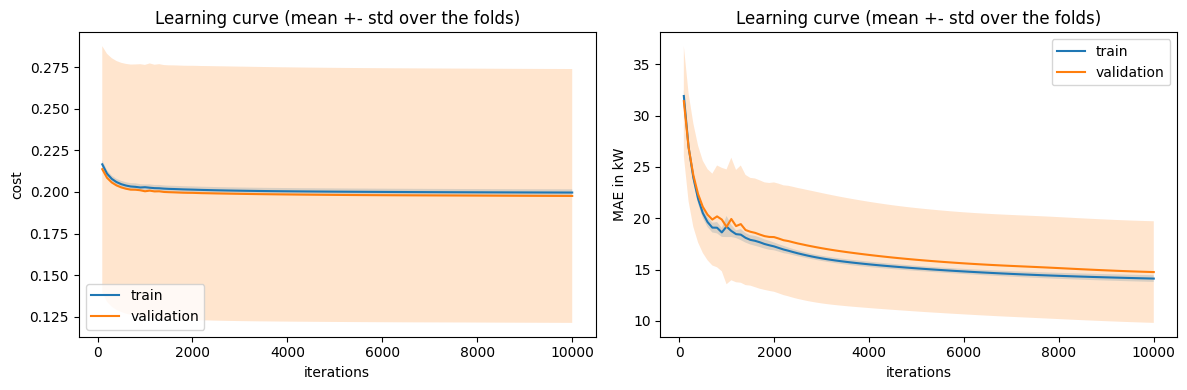

In [18]:
# ---------- learning curves: train vs validation (mean over the CV folds) ----------
total_iterations = 10000   # long enough to see if the validation error starts to rise
step = 100                 # evaluate every 100 iterations
n_points = total_iterations // step

train_cost = np.zeros((n_splits, n_points))
val_cost = np.zeros((n_splits, n_points))
train_mae = np.zeros((n_splits, n_points))
val_mae = np.zeros((n_splits, n_points))

for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    x_train = train_set_x_orig[train_idx]
    x_val = train_set_x_orig[val_idx]
    y_train = train_set_y_orig[train_idx]
    y_val = train_set_y_orig[val_idx]

    # same normalization as in the cross-validation
    scaler_x = MinMaxScaler(feature_range=(0,1))
    scaler_y = MinMaxScaler(feature_range=(0,1))
    x_train_normalized = scaler_x.fit_transform(x_train).T
    x_val_normalized = scaler_x.transform(x_val).T
    y_train_normalized = scaler_y.fit_transform(y_train).T
    y_val_normalized = scaler_y.transform(y_val).T

    y_range = np.max(y_train) - np.min(y_train)    # to convert the normalized error back to kW

    # same initialization as in nn_model
    np.random.seed(3)
    n_x, n_y = layer_sizes(x_train_normalized, y_train_normalized)
    parameters = initialize_parameters(n_x, best_n_h, n_y)

    for k in range(n_points):
        # continue the training for another 100 iterations (same steps as in nn_model)
        for i in range(step):
            A2, cache = forward_propagation(x_train_normalized, parameters)
            grads = backward_propagation(parameters, cache, x_train_normalized, y_train_normalized)
            parameters = update_parameters(parameters, grads, best_learning_rate)

        Y_prediction_train = predict(parameters, x_train_normalized)
        Y_prediction_val = predict(parameters, x_val_normalized)

        train_cost[fold, k] = compute_cost(Y_prediction_train, y_train_normalized)
        val_cost[fold, k] = compute_cost(Y_prediction_val, y_val_normalized)

        train_mae[fold, k] = np.mean(np.abs(Y_prediction_train - y_train_normalized)) * y_range
        val_mae[fold, k] = np.mean(np.abs(Y_prediction_val - y_val_normalized)) * y_range

iterations = np.arange(step, total_iterations + 1, step)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for i, (train_curve, val_curve, label) in enumerate([(train_cost, val_cost, 'cost'), (train_mae, val_mae, 'MAE in kW')]):
    ax[i].plot(iterations, train_curve.mean(axis=0), label='train')
    ax[i].plot(iterations, val_curve.mean(axis=0), label='validation')
    ax[i].set_xlabel('iterations')
    ax[i].set_ylabel(label)
    ax[i].set_title('Learning curve (mean +- std over the folds)')
    ax[i].legend()

plt.tight_layout()
plt.show()

In [19]:
# ---------- final model: whole training set, evaluation on the test set ----------
scaler_x = MinMaxScaler(feature_range=(0,1))
scaler_y = MinMaxScaler(feature_range=(0,1))
train_set_x_normalized = scaler_x.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler_x.transform(test_set_x_orig)
train_set_y_normalized = scaler_y.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler_y.transform(test_set_y_orig)

#Transpose the data to put all features in the rows and all samples in the columns
train_set_x_normalized = train_set_x_normalized.T     # .T Transpose a numpy array
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T

shallow_nn_model = model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, best_n_h, best_num_iterations, best_learning_rate, print_cost=True)

#Reverse normalization
Y_prediction_test_real_scale = scaler_y.inverse_transform(shallow_nn_model["Y_prediction_test"].T)
print("test MAE, RMSE, R2:", evaluate(test_set_y_orig, Y_prediction_test_real_scale))

Cost after iteration 0: 0.693122
Cost after iteration 100: 0.216745
Cost after iteration 200: 0.211205
Cost after iteration 300: 0.208078
Cost after iteration 400: 0.206105
Cost after iteration 500: 0.204819
Cost after iteration 600: 0.203977
Cost after iteration 700: 0.203420
Cost after iteration 800: 0.203060
Cost after iteration 900: 0.202808
Cost after iteration 1000: 0.204252
Cost after iteration 1100: 0.202524
Cost after iteration 1200: 0.202666
Cost after iteration 1300: 0.202294
Cost after iteration 1400: 0.202154
Cost after iteration 1500: 0.202074
Cost after iteration 1600: 0.201945
Cost after iteration 1700: 0.201834
Cost after iteration 1800: 0.201751
Cost after iteration 1900: 0.201675
Cost after iteration 2000: 0.201588
Cost after iteration 2100: 0.201501
Cost after iteration 2200: 0.201425
Cost after iteration 2300: 0.201352
Cost after iteration 2400: 0.201277
Cost after iteration 2500: 0.201206
Cost after iteration 2600: 0.201140
Cost after iteration 2700: 0.201077
Cost

<a name='5'></a>
##  5 - Results Analysis

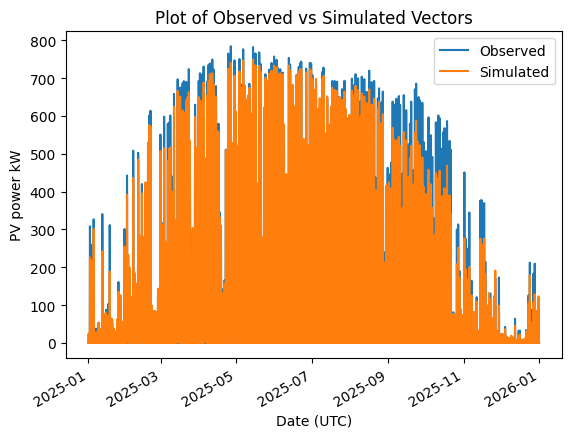

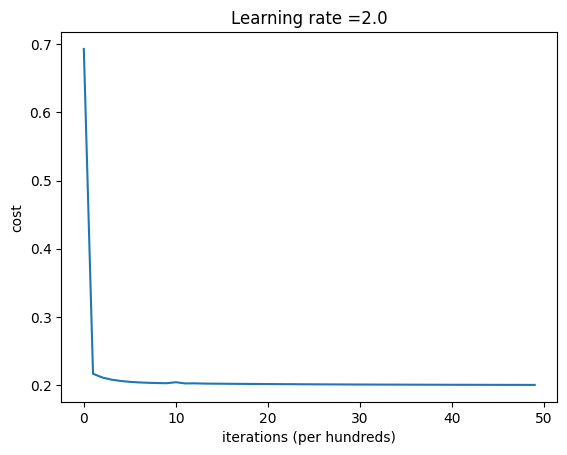

In [20]:
# Results analysis
x = time[split:]                               # datetime index of the test period
y1 = test_set_y_orig
y2 = Y_prediction_test_real_scale

plt.plot(x, y1, label='Observed')
plt.plot(x, y2, label='Simulated')
plt.title('Plot of Observed vs Simulated Vectors')
plt.xlabel('Date (UTC)')
plt.ylabel('PV power kW')
plt.ylim()
plt.legend()
plt.gcf().autofmt_xdate()                    # tilt the date labels
plt.show()

# Plot learning curve (with costs)
costs = np.squeeze(shallow_nn_model['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(shallow_nn_model["learning_rate"]))
plt.show()

